# 가상 염색 (CycleGAN) + 세포 단위 분할 (B 방식) 노트북

커널은 **Python (blood)**, 위에서부터 순서대로 `Shift + Enter`.

```
비염색 영상 → [CycleGAN 가상 염색] → 가상 염색 영상 → [YOLO, conf 0.7] → RBC 개수
                                                        └→ [Cellpose / SAM] → 세포별 윤곽·크기 (B 방식)
```

| 단계 | 하는 일 | 걸리는 시간 |
| --- | --- | --- |
| 0 | 폴더 이동, GPU 확인 | 바로 |
| 1 | 준비 (한 번만): 패키지 설치, CycleGAN 공식 코드 받기, val 분할 | 몇 분 |
| 2 | 하한 다시 재기 (정답 오류 영상 제외 후) | 1~2분 |
| 3 | CycleGAN 학습 (짧은 테스트 → 본 학습) | **본 학습 수 시간** |
| 4 | epoch 고르기 (val 9장) | 수 분 |
| 5 | 최종 채점 (test 91장) — **한 번만** | 1~2분 |
| 6 | 눈으로 확인 | 바로 |
| 7 | B 방식: 세포 윤곽 따기 + 마스크 정확도 | 수 분 |

**데이터 나눔 (섞으면 안 됨)**
- 학습: `3_virtual_staining/rbc_only` (비염색 A = RedTell, 염색 B = TXL-PBC). dse 84~93번은 1번에서 학습에서 뺌
- val (epoch 고르기): `4_eval_unstained/redtell_dse_val` — dse 84~93번 중 9장 (88번은 정답 오류로 제외)
- test (최종 채점): `4_eval_unstained/redtell_dse` — dse 94~186번 중 91장 (97·163번은 정답 오류로 제외)

## 0. 폴더 이동, GPU 확인 (노트북을 열 때마다 먼저 실행)

`!"{sys.executable}" ...` 는 **노트북 커널(blood)과 같은 파이썬**으로 스크립트를 실행하라는 뜻입니다. Jupyter를 base 환경에서 켜도 blood 패키지로 돌아갑니다.


In [1]:
import torch, os, sys
print('GPU 사용 가능:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
os.chdir(r'D:\05. Blood\05. Train\code')
print('현재 폴더:', os.getcwd())
REPO = r"D:/05. Blood/05. Train/external/cyclegan"
print('스크립트 실행 파이썬:', sys.executable)  # envs\\blood 여야 정상

GPU 사용 가능: True NVIDIA GeForce RTX 5060 Ti
현재 폴더: D:\05. Blood\05. Train\code
스크립트 실행 파이썬: C:\Users\KonYang\anaconda3\envs\blood\python.exe


## 1. 준비 (처음 한 번만)

### 1-1. CycleGAN 공식 코드가 쓰는 패키지 설치

In [2]:
%pip install dominate wandb scikit-image openpyxl

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.9 MB 7.7 MB/s eta 0:00:02
   ------- -------------------------------- 2.4/11.9 MB 6.1 MB/s eta 0:00:02
   ---------- ----------------------------- 3.1/11.9 MB 5.0 MB/s eta 0:00:02
   ------------- -------------------------- 3.9/11.9 MB 4.5 MB/s eta 0:00:02
   --------------- ------------------------ 4.5/11.9 MB 4.3 MB/s eta 0:00:02
   ---------------- ----------------------- 5.0/11.9 MB 4.1 MB/s eta 0:00:02
   ------------------- -------------------- 5.8/11.9 MB 3.9 MB/s eta 0:00:02
   --------------------- ------------------ 6.3/11.9 MB 3.8 MB/s eta 0:00:02
   ----------------------- ---------------- 7.1/11.9 MB 3.7 MB/s eta 0:00:02
   ------------------------- -------------- 7.6/11.9 MB 3.6 MB/s eta 0:00:02
   ---------------------------- ----------- 8.4/11.9 MB 3.6 MB/s eta 0:00:01
   ------------------------------ --------- 8.9/11.9 MB 3.5 MB/s eta 0:00:01
   ---

### 1-2. CycleGAN 공식 코드 받기
저자 공식 저장소(junyanz/pytorch-CycleGAN-and-pix2pix)를 `05. Train/external/cyclegan`에 받고, 테스트한 버전(2025-08, `2a7afba`)으로 고정합니다.

In [3]:
!git clone https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git "D:/05. Blood/05. Train/external/cyclegan"
!git -C "D:/05. Blood/05. Train/external/cyclegan" checkout 2a7afba

fatal: destination path 'D:/05. Blood/05. Train/external/cyclegan' already exists and is not an empty directory.
HEAD is now at 2a7afba fix bugs (when use wandb without torchrun)


### 1-3. val 분할 만들기 + 정답 오류 영상 제외
- dse 84~93번 조각을 학습(trainA)에서 빼서 `_holdout_val`로 옮김 (삭제 아님)
- `4_eval_unstained/redtell_dse_val` 생성 (9장)
- 최종 채점셋에서 97·163번을 `_excluded_bad_gt`로 옮김 (정답 마스크가 영상과 안 맞음)

In [4]:
!"{sys.executable}" 20_make_staining_val.py --prep "D:/05. Blood/04. Prep" --dse_zip "D:/05. Blood/03. Data/6. RedTell/dse_data.zip"

[rbc_only] trainA 에서 275개 이동 → _holdout_val (남은 trainA 4651개)
[all] trainA 에서 225개 이동 → _holdout_val (남은 trainA 4075개)
[test] redtell_dse 에서 [97, 163]번 제외 → 영상 91장, 정답 RBC 3512개
[val] D:/05. Blood/04. Prep\4_eval_unstained\redtell_dse_val : 영상 9장, 정답 RBC 338개


## 2. 하한 다시 재기 — 가상 염색 없이 비염색을 그대로 YOLO에 (정답 오류 제외 후)
가상 염색 결과와 비교할 기준선입니다. 같은 YOLO, 같은 conf 0.7.

In [5]:
for split, d in [("val", "redtell_dse_val"), ("test", "redtell_dse")]:
    !"{sys.executable}" 12_eval_compare.py --prep "D:/05. Blood/04. Prep" --images "D:/05. Blood/04. Prep/4_eval_unstained/{d}/images" --labels "D:/05. Blood/04. Prep/4_eval_unstained/{d}/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --out "D:/05. Blood/07. Evaluate/2_no_staining/stain_none_{split}"


[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 10.111
  RBC_precision: 0.9757
  RBC_recall: 0.713
  RBC_F1: 0.8239
  WBC_rel_error: 
  RBC_rel_error: 0.2708
  ms_per_image: 13.9

����옣: D:/05. Blood/05. Train/results/stain_none_val

[YOLO]
  method: YOLO
  n_images: 91
  WBC_MAE: 0.011
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 9.846
  RBC_precision: 0.9736
  RBC_recall: 0.7252
  RBC_F1: 0.8313
  WBC_rel_error: 
  RBC_rel_error: 0.2695
  ms_per_image: 11.8

����옣: D:/05. Blood/05. Train/results/stain_none_test


In [6]:
import pandas as pd
cols = ["n_images", "RBC_MAE", "RBC_precision", "RBC_recall", "RBC_F1", "RBC_rel_error"]
display(pd.concat([pd.read_csv(rf"D:/05. Blood/07. Evaluate/2_no_staining/stain_none_{s}/summary.csv").assign(split=s) for s in ["val", "test"]])[["split"] + cols])

,split,n_images,RBC_MAE,RBC_precision,RBC_recall,RBC_F1,RBC_rel_error
0,val,9,10.111,0.9757,0.7130,0.8239,0.2708
0,test,91,9.846,0.9736,0.7252,0.8313,0.2695


## 3. CycleGAN 학습

### 3-1. 짧은 테스트 (1~2분) — 본 학습 전에 에러가 없는지 확인
끝에 `End of epoch 1 / 1`이 나오면 성공입니다. 출력의 `time:` 값이 **1장 처리 시간(초)** 이라 본 학습 시간 예상에 씁니다.

In [7]:
!"{sys.executable}" "D:/05. Blood/05. Train/external/cyclegan/train.py" --dataroot "D:/05. Blood/04. Prep/3_virtual_staining/rbc_only" --name cyclegan_smoke --model cycle_gan --checkpoints_dir "D:/05. Blood/05. Train/runs/cyclegan" --preprocess none --load_size 128 --crop_size 128 --n_epochs 1 --n_epochs_decay 0 --max_dataset_size 200 --num_threads 0 --print_freq 50 --display_freq 100000

----------------- Options ---------------
               batch_size: 1                             
                    beta1: 0.5                           
          checkpoints_dir: D:/05. Blood/05. Train/runs/cyclegan	[default: ./checkpoints]
           continue_train: False                         
                crop_size: 128                           	[default: 256]
                 dataroot: D:/05. Blood/04. Prep/3_virtual_staining/rbc_only	[default: None]
             dataset_mode: unaligned                     
                direction: AtoB                          
             display_freq: 100000                        	[default: 400]
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 1                             
                 gan_mode: lsgan                         
                init_gain: 0.02                          
                init_type: normal                 

D:\05. Blood\05. Train\external\cyclegan\models\base_model.py:182: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  errors_ret[name] = float(getattr(self, "loss_" + name))  # float(...) works for both scalar tensor and float number


### 3-2. 본 학습 (수 시간)
- 설정: 공식 기본값 그대로 + **50 epoch** (25 + 학습률 감소 25), 128×128 조각, 5 epoch마다 가중치 저장
- 1 epoch ≈ 4,800 iteration. 예상 시간 ≈ 3-1의 `time` × 4,800 × 50 초
- **학습 중에는 노트북 창을 닫지 마세요.** 중간에 끊기면 아래 명령 끝에 `--continue_train --epoch_count <다음 epoch>` 를 붙여 이어서 할 수 있습니다.
- 진행 상황: `runs/cyclegan/cyclegan_rbc/loss_log.txt`, 중간 결과 그림: `runs/cyclegan/cyclegan_rbc/web/index.html`
- `--num_threads 0`: 윈도우에서 데이터 로더 에러를 피하기 위함

In [8]:
!"{sys.executable}" "D:/05. Blood/05. Train/external/cyclegan/train.py" --dataroot "D:/05. Blood/04. Prep/3_virtual_staining/rbc_only" --name cyclegan_rbc --model cycle_gan --checkpoints_dir "D:/05. Blood/05. Train/runs/cyclegan" --preprocess none --load_size 128 --crop_size 128 --n_epochs 25 --n_epochs_decay 25 --save_epoch_freq 5 --num_threads 0 --print_freq 1000 --display_freq 5000 --update_html_freq 5000

----------------- Options ---------------
               batch_size: 1                             
                    beta1: 0.5                           
          checkpoints_dir: D:/05. Blood/05. Train/runs/cyclegan	[default: ./checkpoints]
           continue_train: False                         
                crop_size: 128                           	[default: 256]
                 dataroot: D:/05. Blood/04. Prep/3_virtual_staining/rbc_only	[default: None]
             dataset_mode: unaligned                     
                direction: AtoB                          
             display_freq: 5000                          	[default: 400]
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 1                             
                 gan_mode: lsgan                         
                init_gain: 0.02                          
                init_type: normal                 

D:\05. Blood\05. Train\external\cyclegan\models\base_model.py:182: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  errors_ret[name] = float(getattr(self, "loss_" + name))  # float(...) works for both scalar tensor and float number


## 4. epoch 고르기 (val 9장으로만)
5 epoch마다 저장된 가중치로 val을 가상 염색 → YOLO(conf 0.7)로 채점합니다.
**고르는 규칙 (미리 정함): val RBC F1이 가장 높은 epoch.** test는 여기서 보지 않습니다.

In [9]:
EPOCHS = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
for e in EPOCHS:
    !"{sys.executable}" 21_apply_cyclegan.py --repo "D:/05. Blood/05. Train/external/cyclegan" --ckpt "D:/05. Blood/05. Train/runs/cyclegan/cyclegan_rbc" --epoch {e} --images "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse_val/images" --out "D:/05. Blood/06. Generate/cyclegan/ep{e}/val"
    !"{sys.executable}" 12_eval_compare.py --prep "D:/05. Blood/04. Prep" --images "D:/05. Blood/06. Generate/cyclegan/ep{e}/val" --labels "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse_val/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --out "D:/05. Blood/07. Evaluate/3_staining/cyclegan/ep{e}_val"

가상 염색 9장 완료 (epoch 5, 장당 96 ms) → D:/05. Blood/05. Train/virtual_stained/cyclegan_ep5/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 9.889
  RBC_precision: 0.7088
  RBC_recall: 0.8787
  RBC_F1: 0.7847
  WBC_rel_error: 
  RBC_rel_error: 0.3635
  ms_per_image: 12.2

����옣: D:/05. Blood/05. Train/results/stain_cyclegan_ep5_val
가상 염색 9장 완료 (epoch 10, 장당 90 ms) → D:/05. Blood/05. Train/virtual_stained/cyclegan_ep10/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 8.444
  RBC_precision: 0.7146
  RBC_recall: 0.8669
  RBC_F1: 0.7834
  WBC_rel_error: 
  RBC_rel_error: 0.3207
  ms_per_image: 11.1

����옣: D:/05. Blood/05. Train/results/stain_cyclegan_ep10_val
가상 염색 9장 완료 (epoch 15, 장당 88 ms) → D:/05. Blood/05. Train/virtual_stained/cyclegan_ep15/val

[YOLO]
  method: YOLO
  n_images: 9
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  

In [10]:
import pandas as pd
rows = [pd.read_csv(rf"D:/05. Blood/07. Evaluate/2_no_staining/stain_none_val/summary.csv").assign(epoch="가상 염색 없음")]
rows += [pd.read_csv(rf"D:/05. Blood/07. Evaluate/3_staining/cyclegan/ep{e}_val/summary.csv").assign(epoch=e) for e in EPOCHS]
tab = pd.concat(rows)[["epoch", "RBC_MAE", "RBC_precision", "RBC_recall", "RBC_F1"]]
display(tab)
best = tab[tab.epoch != "가상 염색 없음"].sort_values("RBC_F1", ascending=False).iloc[0]
print("val RBC F1 최고 epoch:", best.epoch)

,epoch,RBC_MAE,RBC_precision,RBC_recall,RBC_F1
0,가상 염색 없음,10.111,0.9757,0.7130,0.8239
0,5,9.889,0.7088,0.8787,0.7847
0,10,8.444,0.7146,0.8669,0.7834
0,15,6.333,0.7519,0.8787,0.8104
0,20,11.556,0.6448,0.8432,0.7308
0,25,9.222,0.7150,0.8905,0.7931
0,30,8.333,0.8399,0.6982,0.7625
0,35,37.444,0.0000,0.0000,0.0000
0,40,37.556,0.0000,0.0000,0.0000
0,45,37.222,0.0000,0.0000,0.0000


val RBC F1 최고 epoch: 15


## 5. 최종 채점 (test 91장) — 고른 epoch로 **한 번만**
아래 `BEST_EPOCH`를 4번에서 나온 값으로 바꾸고 실행하세요.

In [12]:
BEST_EPOCH = 15   # ← 4번 결과로 바꾸기
!"{sys.executable}" 21_apply_cyclegan.py --repo "D:/05. Blood/05. Train/external/cyclegan" --ckpt "D:/05. Blood/05. Train/runs/cyclegan/cyclegan_rbc" --epoch {BEST_EPOCH} --images "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/images" --out "D:/05. Blood/06. Generate/cyclegan/ep{BEST_EPOCH}/test"
!"{sys.executable}" 12_eval_compare.py --prep "D:/05. Blood/04. Prep" --images "D:/05. Blood/06. Generate/cyclegan/ep{BEST_EPOCH}/test" --labels "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/labels" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --out "D:/05. Blood/07. Evaluate/3_staining/cyclegan/ep{BEST_EPOCH}_test"

가상 염색 91장 완료 (epoch 50, 장당 91 ms) → D:/05. Blood/05. Train/virtual_stained/cyclegan_ep50/test
가상 염색 91장 완료 (epoch 15, 장당 81 ms) → D:/05. Blood/05. Train/virtual_stained/cyclegan_ep15/test

[YOLO]
  method: YOLO
  n_images: 91
  WBC_MAE: 0.0
  WBC_precision: 0.0
  WBC_recall: 0.0
  WBC_F1: 0.0
  RBC_MAE: 7.769
  RBC_precision: 0.7073
  RBC_recall: 0.8388
  RBC_F1: 0.7675
  WBC_rel_error: 
  RBC_rel_error: 0.299
  ms_per_image: 12.6

����옣: D:/05. Blood/05. Train/results/stain_cyclegan_ep15_test


In [13]:
import pandas as pd
cols = ["method", "RBC_MAE", "RBC_precision", "RBC_recall", "RBC_F1", "RBC_rel_error"]
a = pd.read_csv(rf"D:/05. Blood/07. Evaluate/2_no_staining/stain_none_test/summary.csv").assign(method="가상 염색 없음 (하한)")
b = pd.read_csv(rf"D:/05. Blood/07. Evaluate/3_staining/cyclegan/ep{BEST_EPOCH}_test/summary.csv").assign(method=f"CycleGAN ep{BEST_EPOCH}")
display(pd.concat([a, b])[cols])

,method,RBC_MAE,RBC_precision,RBC_recall,RBC_F1,RBC_rel_error
0,가상 염색 없음 (하한),9.846,0.9736,0.7252,0.8313,0.2695
0,CycleGAN ep15,7.769,0.7073,0.8388,0.7675,0.2990


## 6. 눈으로 확인 (평가 ①)
위: 비염색 입력 / 아래: 가상 염색 결과. **없는 핵·세포가 생기거나 세포가 사라졌는지** 봐 주세요.

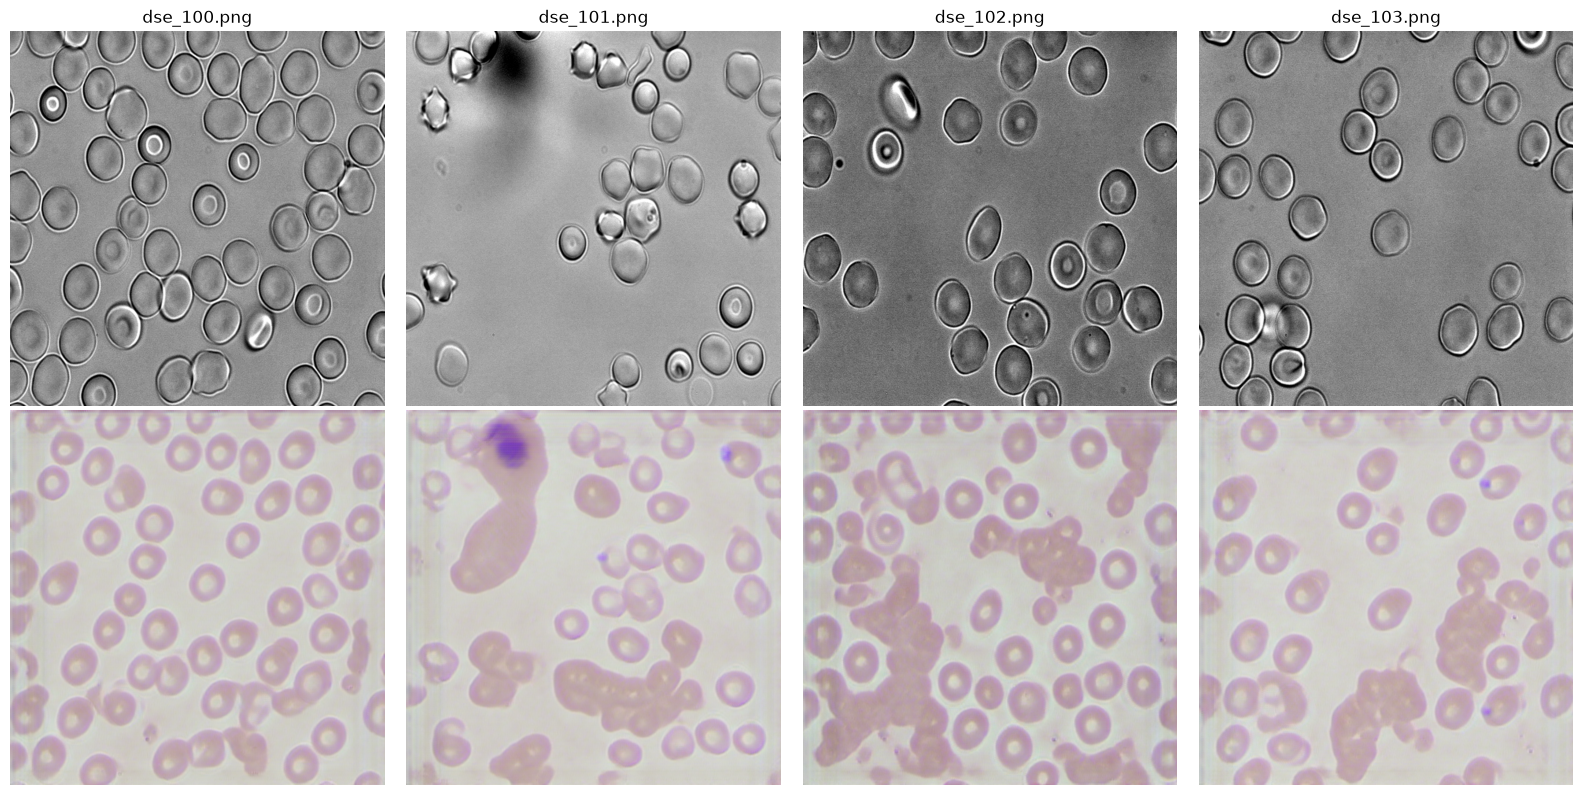

In [14]:
import matplotlib.pyplot as plt, numpy as np, cv2, glob, os
names = sorted(os.listdir(rf"D:/05. Blood/06. Generate/cyclegan/ep{BEST_EPOCH}/test"))[:4]
fig, ax = plt.subplots(2, len(names), figsize=(4 * len(names), 8))
for i, n in enumerate(names):
    src = cv2.imdecode(np.fromfile(rf"D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/images/{n}", np.uint8), 0)
    vs = cv2.imdecode(np.fromfile(rf"D:/05. Blood/06. Generate/cyclegan/ep{BEST_EPOCH}/test/{n}", np.uint8), 1)
    ax[0, i].imshow(src, cmap="gray"); ax[0, i].set_title(n)
    ax[1, i].imshow(cv2.cvtColor(vs, cv2.COLOR_BGR2RGB))
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

## 7. B 방식: YOLO 박스 → 세포 윤곽 (세포 단위 결과)
같은 YOLO 박스에 윤곽 따는 방법 3가지를 붙여 비교합니다. 정답 마스크(RBC)로 정확도를 잽니다.
- `cellpose`: 영상 전체를 Cellpose로 분할 → YOLO 박스와 가장 잘 겹치는 세포를 배정
- `sam`: YOLO 박스를 SAM 2.1에 넣어 박스마다 윤곽 (처음 실행 때 가중치 약 75MB 자동 다운로드)
- `ellipse`: 박스 안 타원 (모델 없는 기준선)

결과: `07. Evaluate/4_cell_mask/cellmask_.../<방식>/cells.csv` (세포마다 면적·둘레·원형도·지름), `overlay/` 확인 그림

In [15]:
for tag, img_dir in [("none", "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/images"),
                     (f"cyclegan_ep{BEST_EPOCH}", f"D:/05. Blood/06. Generate/cyclegan/ep{BEST_EPOCH}/test")]:
    !"{sys.executable}" 13_cell_masks.py --images "{img_dir}" --yolo "D:/05. Blood/05. Train/runs/yolo/yolo11s/weights/best.pt" --conf 0.7 --mask cellpose sam ellipse --gt_masks "D:/05. Blood/04. Prep/4_eval_unstained/redtell_dse/masks" --out "D:/05. Blood/07. Evaluate/4_cell_mask/cellmask_{tag}_test"


[cellpose]
  mask_method: cellpose
  n_images: 91
  n_cells_detected: 2617
  mask_coverage: 0.9985
  ms_per_image_yolo: 27.1
  ms_per_image_mask: 843.7
  seg_precision: 0.9782
  seg_recall: 0.7278
  seg_F1: 0.8346
  mean_IoU_matched: 0.8153
  area_rel_error: 0.2259
WARNING Download failure, retrying 1/3 in 5s https://github.com/ultralytics/assets/releases/download/v8.4.0/sam2.1_t.pt... HTTPSConnectionPool(host='release-assets.githubusercontent.com', port=443): Max retries exceeded with url: /github-production-release-asset/521807533/159cc87b-e4c3-463e-8717-5f79d8fee495?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-30T01%3A09%3A02Z&rscd=attachment%3B+filename%3Dsam2.1_t.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-30T00%3A08%3A12Z&ske=2026-10-30T01%3A09%3A02Z&sks=b&skv=2018-11-09&sig=Fxlv2WNtq1kA2p5PX%2BuggG1pvJP3cY08kedDvtOLkk8%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwi

C:\Users\KonYang\anaconda3\envs\blood\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),



[cellpose]
  mask_method: cellpose
  n_images: 91
  n_cells_detected: 4165
  mask_coverage: 0.9726
  ms_per_image_yolo: 27.3
  ms_per_image_mask: 845.8
  seg_precision: 0.7408
  seg_recall: 0.8545
  seg_F1: 0.7936
  mean_IoU_matched: 0.7262
  area_rel_error: 0.1537

[sam]
  mask_method: sam
  n_images: 91
  n_cells_detected: 4165
  mask_coverage: 1.0
  ms_per_image_yolo: 27.3
  ms_per_image_mask: 126.4
  seg_precision: 0.7301
  seg_recall: 0.8659
  seg_F1: 0.7922
  mean_IoU_matched: 0.7283
  area_rel_error: 0.1361

[ellipse]
  mask_method: ellipse
  n_images: 91
  n_cells_detected: 4165
  mask_coverage: 1.0
  ms_per_image_yolo: 27.3
  ms_per_image_mask: 7.2
  seg_precision: 0.7011
  seg_recall: 0.8314
  seg_F1: 0.7607
  mean_IoU_matched: 0.6749
  area_rel_error: 0.3628

����옣: D:/05. Blood/05. Train/results/cellmask_cyclegan_ep15_test


C:\Users\KonYang\anaconda3\envs\blood\Lib\site-packages\cellpose\dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:767.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


In [16]:
import pandas as pd
cols = ["input", "mask_method", "mask_coverage", "seg_precision", "seg_recall", "seg_F1", "mean_IoU_matched", "area_rel_error", "ms_per_image_mask"]
t = pd.concat([pd.read_csv(rf"D:/05. Blood/07. Evaluate/4_cell_mask/cellmask_{tag}_test/summary.csv").assign(input=tag) for tag in ["none", f"cyclegan_ep{BEST_EPOCH}"]])
display(t[cols])

,input,mask_method,mask_coverage,seg_precision,seg_recall,seg_F1,mean_IoU_matched,area_rel_error,ms_per_image_mask
0,none,cellpose,0.9985,0.9782,0.7278,0.8346,0.8153,0.2259,843.7
1,none,sam,1.0000,0.9748,0.7261,0.8322,0.8188,0.2193,105.9
2,none,ellipse,1.0000,0.9717,0.7238,0.8296,0.7846,0.2515,5.2
0,cyclegan_ep15,cellpose,0.9726,0.7408,0.8545,0.7936,0.7262,0.1537,845.8
1,cyclegan_ep15,sam,1.0000,0.7301,0.8659,0.7922,0.7283,0.1361,126.4
2,cyclegan_ep15,ellipse,1.0000,0.7011,0.8314,0.7607,0.6749,0.3628,7.2
